# FallacyLens — Final Experiment Notebook

Phases 2–3: controlled model comparison, direct climate transfer, ablations, error analysis, and token sensitivity. See `report/FINAL_REPORT.md` for interpretation and limitations. All displayed scores are loaded from saved predictions generated by `train_final.py`.

## 1. Reproduce the measured outputs
The first cell runs the full experiment only when its metrics file is absent, then generates analysis artifacts. It may take several minutes on CPU and downloads the official dataset and pretrained model on first use.

In [1]:
from pathlib import Path
import subprocess, sys, json
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
if not (ROOT / "train_final.py").exists(): ROOT = ROOT.parent
if not (ROOT / "results/final/metrics.json").exists():
    subprocess.run([sys.executable, str(ROOT / "train_final.py")], check=True, cwd=ROOT)
if not (ROOT / "results/final/comparison_with_baseline.csv").exists():
    subprocess.run([sys.executable, str(ROOT / "analyze_final.py")], check=True, cwd=ROOT)
print("Artifacts:", ROOT / "results/final")

Artifacts: /Users/lakshitsachdeva/Desktop/college/DLPROJ/results/final


## 2. Data protocol and leakage audit
The strict test excludes released test texts appearing in train or dev. No test labels drive fitting or model selection.

In [2]:
protocol = json.loads((ROOT / "results/final/protocol.json").read_text())
for key in ["original_rows", "conflicting_train_texts", "train_after_conflicts", "train_after_dedup", "final_rows", "train_test_overlap_rows", "dev_test_overlap_rows", "test_rows_excluded_for_prior_text_exposure", "vocab_size", "seed"]:
    print(f"{key}: {protocol[key]}")

original_rows: {'train': 1849, 'dev': 300, 'test': 300}
conflicting_train_texts: 5
train_after_conflicts: 1839
train_after_dedup: 1814
final_rows: {'train': 1801, 'dev': 300, 'test': 300, 'test_exclusive': 283, 'climate_test': 211}
train_test_overlap_rows: 11
dev_test_overlap_rows: 6
test_rows_excluded_for_prior_text_exposure: 17
vocab_size: 3124
seed: 42


## 3. Held-out comparison
Macro F1 is the main metric. The majority baseline predicts the most frequent training label for every row. The selected model is chosen by dev macro F1 only.

In [3]:
comparison = pd.read_csv(ROOT / "results/final/comparison_with_baseline.csv")
display(comparison.round(4))
selection = json.loads((ROOT / "results/final/selection.json").read_text())
print("Selected by dev:", selection["selected_by_dev"])

,model,split,n,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
0,majority,dev,300,0.2033,0.0156,0.0769,0.0260,0.0687
1,majority,test,300,0.2033,0.0156,0.0769,0.0260,0.0687
2,majority,test_exclusive,283,0.2014,0.0155,0.0769,0.0258,0.0675
3,majority,climate_test,211,0.1327,0.0102,0.0769,0.0180,0.0311
4,cnn,dev,300,0.5100,0.5268,0.4259,0.4421,0.4992
5,cnn,test,300,0.5033,0.4565,0.4395,0.4314,0.4782
6,cnn,test_exclusive,283,0.4841,0.4329,0.4206,0.4075,0.4551
7,cnn,climate_test,211,0.1185,0.0740,0.1002,0.0800,0.0933
8,bilstm,dev,300,0.4233,0.3522,0.3357,0.3297,0.4090
9,bilstm,test,300,0.3967,0.3528,0.3109,0.3175,0.3746


Selected by dev: cnn


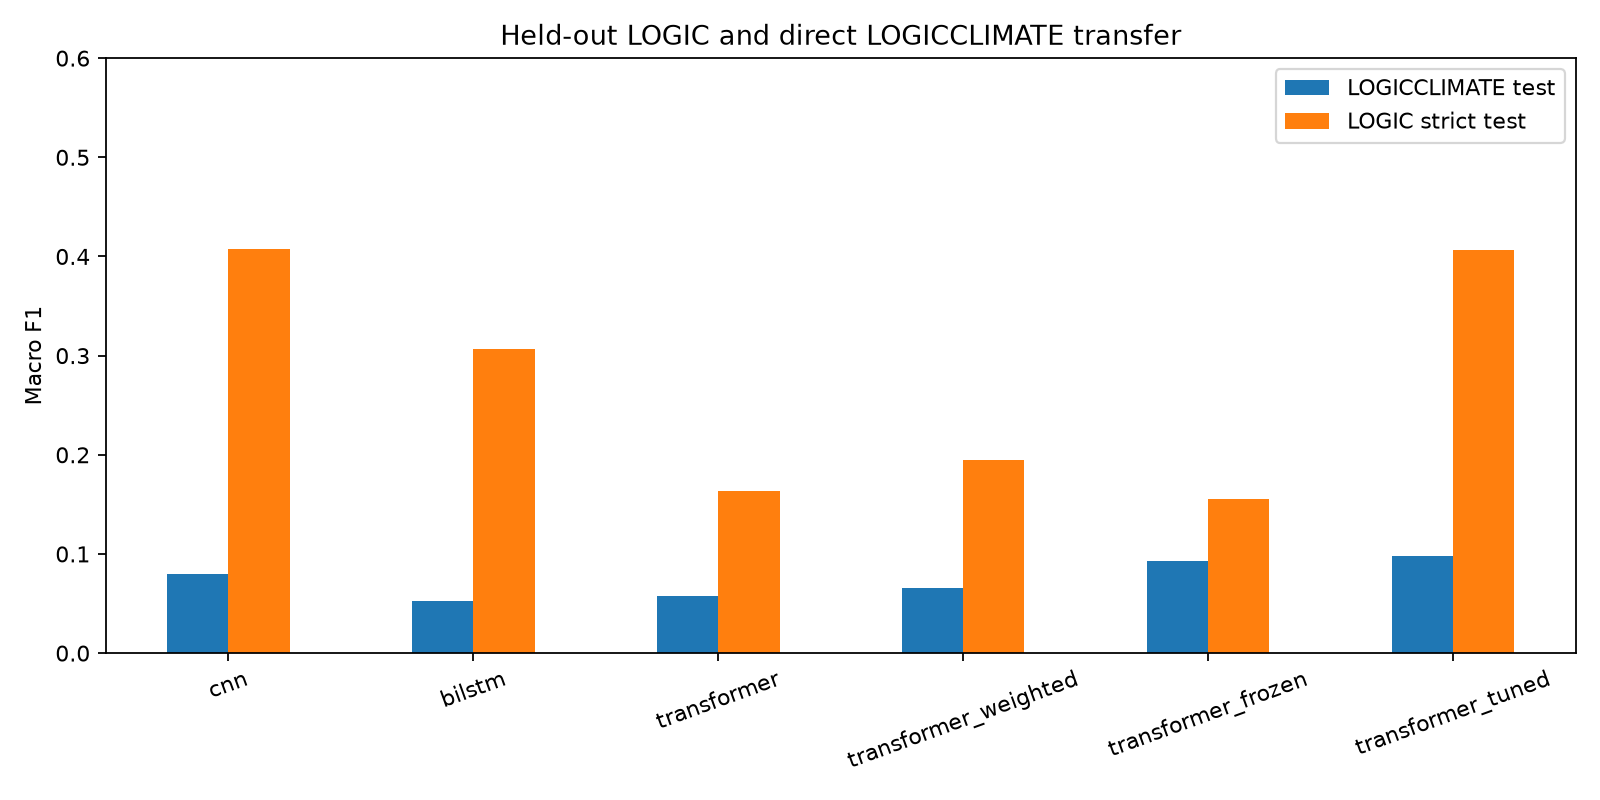

In [4]:
display(Image(filename=str(ROOT / "figures/final/comparison.png")))

## 4. Per-class and uncertainty analysis
The bootstrap interval quantifies uncertainty from sampling strict-test rows. It does not measure run-to-run training variance.

In [5]:
display(pd.read_csv(ROOT / "results/final/selected_per_class.csv").round(3))
print(json.dumps(json.loads((ROOT / "results/final/uncertainty.json").read_text()), indent=2))

,label,precision,recall,f1,support
0,ad hominem,0.562,0.711,0.628,38
1,ad populum,0.593,0.552,0.571,29
2,appeal to emotion,0.375,0.286,0.324,21
3,circular reasoning,0.611,0.579,0.595,19
4,equivocation,0.000,0.000,0.000,5
5,fallacy of credibility,0.143,0.059,0.083,17
6,fallacy of extension,0.588,0.500,0.541,20
7,fallacy of logic,0.571,0.286,0.381,14
8,fallacy of relevance,0.300,0.130,0.182,23
9,false causality,0.310,0.562,0.400,16


{
  "method": "2000 paired row bootstrap replicates, seed 42; fixed 13-label macro F1",
  "selected_model": "cnn",
  "runner_up_by_dev": "transformer_tuned",
  "strict_test_macro_f1_95pct_interval": [
    0.3479424573371904,
    0.45700042478477054
  ],
  "selected_minus_runner_up_95pct_interval": [
    -0.05916276208771952,
    0.06330930677457824
  ],
  "selected_minus_runner_up_point": 0.0007855666675488093
}


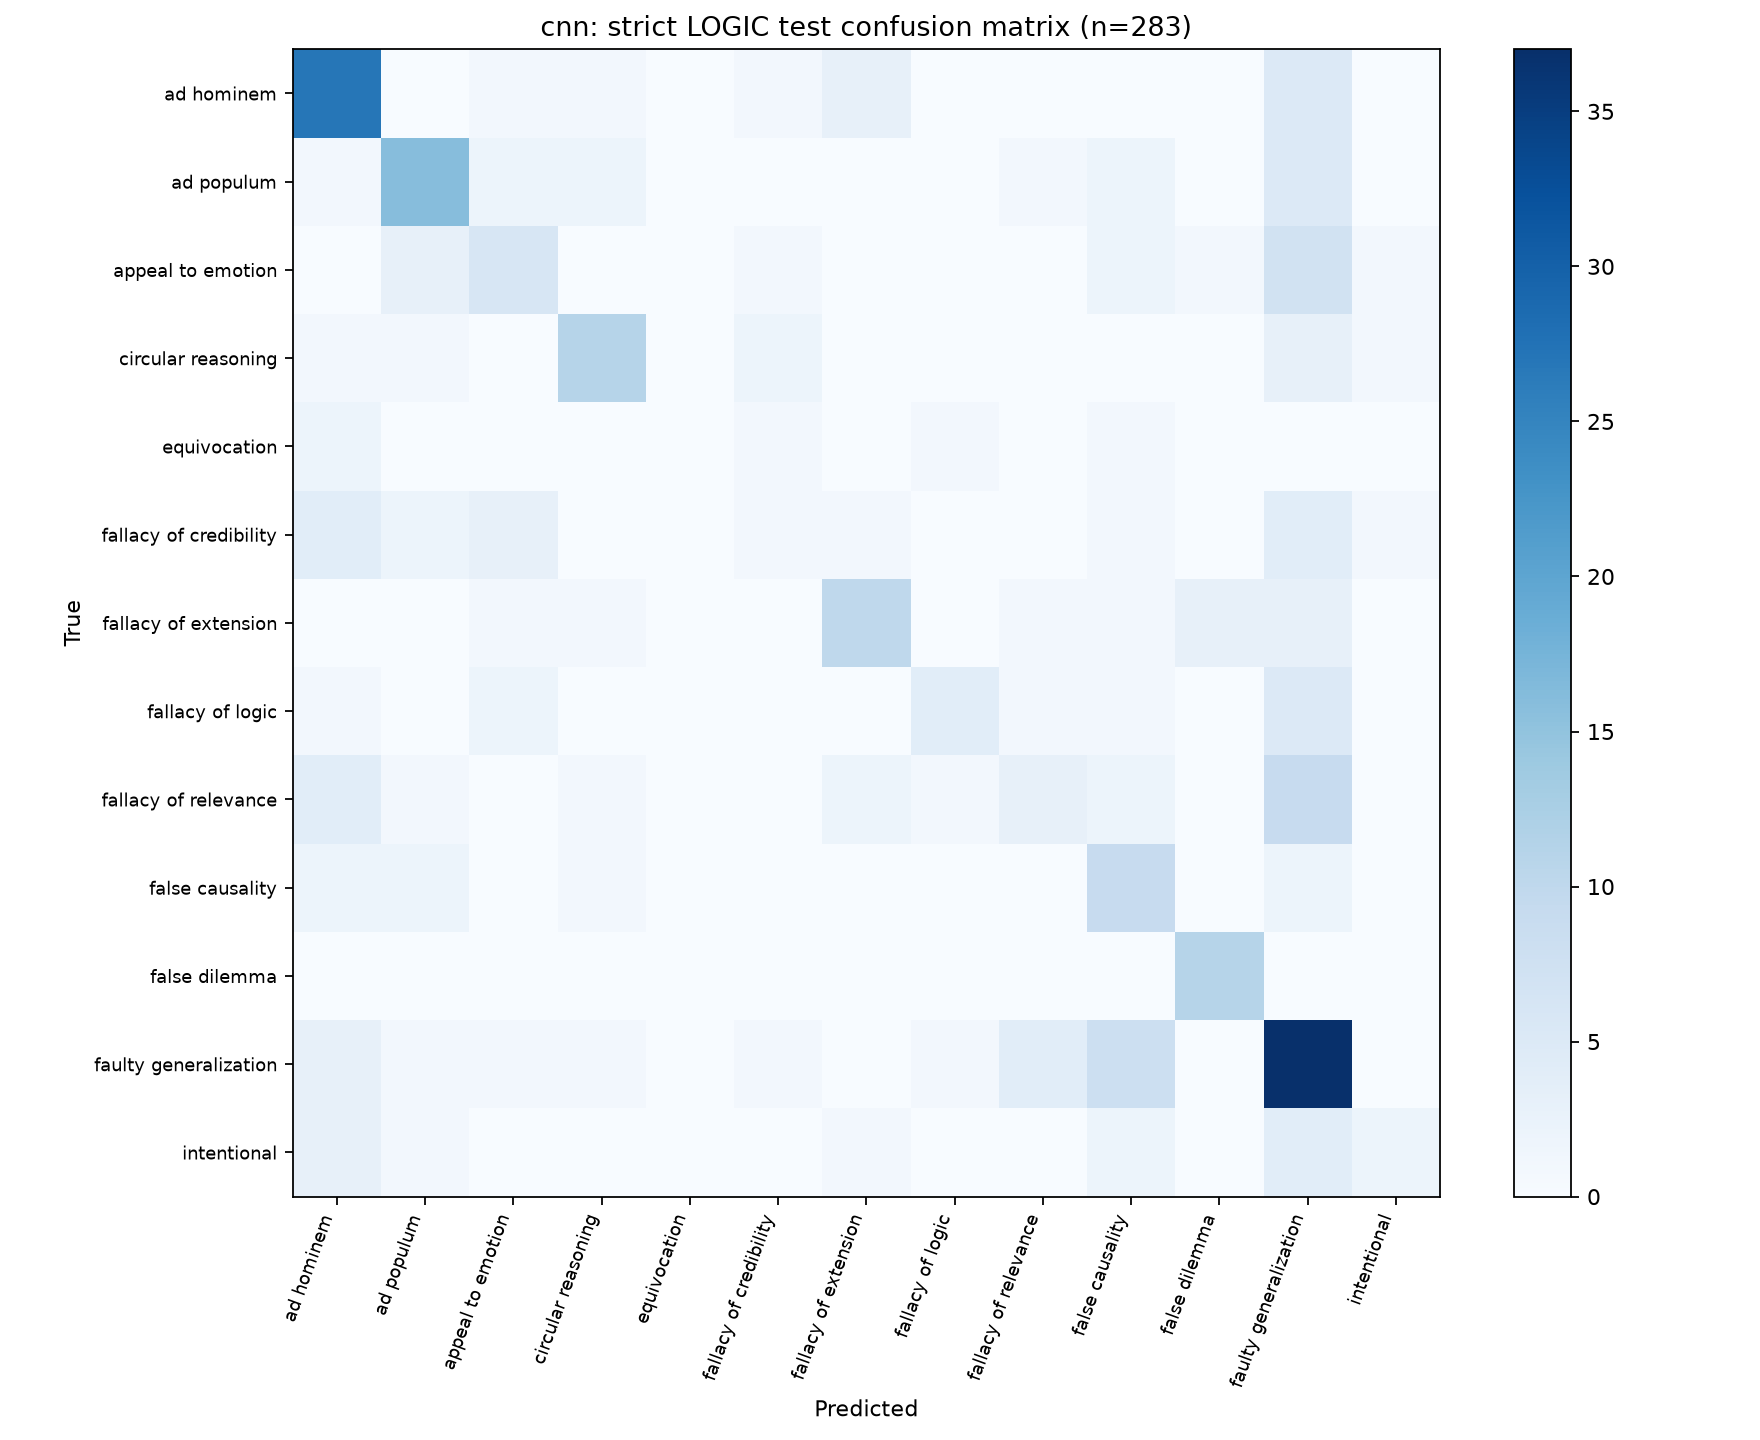

In [6]:
display(Image(filename=str(ROOT / "figures/final/confusion_matrix.png")))

## 5. Error analysis and local sensitivity
Saved errors are actual test rows. Token deletion shows which replacements most changed the selected model's own predicted score; it is not a proof of reasoning.

In [7]:
details = ROOT / "results/final/selected_errors.csv"
sensitivity = ROOT / "results/final/token_sensitivity.csv"
if details.exists() and sensitivity.exists():
    display(pd.read_csv(details).drop(columns=["text"]).head(10))
    display(pd.read_csv(sensitivity).drop(columns=["text"]).head(10))
else:
    print("Row-level details are regenerated locally by train_final.py and analyze_final.py.")

,label,predicted,confidence,correct
0,ad populum,circular reasoning,0.991294,False
1,ad populum,circular reasoning,0.968009,False
2,appeal to emotion,intentional,0.955364,False
3,fallacy of extension,fallacy of relevance,0.955007,False
4,fallacy of logic,faulty generalization,0.910422,False
5,fallacy of logic,faulty generalization,0.874124,False
6,fallacy of extension,faulty generalization,0.863287,False
7,appeal to emotion,ad populum,0.833392,False
8,circular reasoning,faulty generalization,0.801514,False
9,appeal to emotion,faulty generalization,0.783843,False


,row,correct,true,pred,confidence,top_deletion_tokens
0,2,False,fallacy of logic,faulty generalization,0.564753,year (+0.179); than (+0.159); lower (+0.149); ...
1,8,False,fallacy of credibility,fallacy of extension,0.224291,want (+0.162); to (+0.124); would (+0.107); sa...
2,9,False,circular reasoning,fallacy of credibility,0.147084,that (+0.041); something (+0.033); is (+0.030)...
3,11,False,faulty generalization,false causality,0.371328,therefore (+0.296); ; (+0.148); 2 (+0.060); ; ...
4,12,False,ad hominem,faulty generalization,0.649557,their (+0.155); ; (+0.105); than (+0.091); ” (...
5,0,True,fallacy of extension,fallacy of extension,0.340244,drive (+0.251); hate (+0.233); probably (+0.20...
6,1,True,faulty generalization,faulty generalization,0.682149,men (+0.251); . (+0.228); no (+0.123); jump (+...
7,3,True,false causality,false causality,0.723181,time (+0.375); was (+0.306); my (+0.245); weak...
8,4,True,faulty generalization,faulty generalization,0.971595,all (+0.121); bad (+0.058); good (+0.054); and...
9,5,True,fallacy of extension,fallacy of extension,0.930232,state (+0.443); proposed (+0.300); wage (+0.23...


## 6. Conclusion
Interpret the in-domain and climate results together. The text classifier has no no-fallacy class or fact checker. See the final report for the measured conclusions, methodological limits, and source references.